# Sistema de Recomendación de Música con Machine Learning

**Fuente original:** https://www.geeksforgeeks.org/machine-learning/music-recommendation-system-using-machine-learning/

**Modificador y ejecutor:** Carlos Francisco Montoya Urzua

---

¿Alguna vez te preguntaste cómo, después de ver un video gracioso en YouTube, la próxima vez que abres la app te aparecen recomendaciones de videos similares? Esto es precisamente una aplicación del **Machine Learning**, con el cual se construyen **sistemas de recomendación** para ofrecer experiencias personalizadas y aumentar la interacción con los usuarios.

En este notebook, recorremos el proceso de construcción de un **sistema de recomendación de música basado en contenido** usando machine learning. El sistema recomienda canciones similares a una canción de entrada, basándose en metadatos como el género, el nombre del artista y el nombre de la pista. Utilizaremos el dataset **"TCC CEDs Music Dataset"**, que contiene metadatos sobre canciones, incluyendo géneros, artistas y letras.

---
**Descarga el dataset:** https://media.geeksforgeeks.org/wp-content/uploads/20250402152109933965/tcc_ceds_music.csv

## Paso 1: Importar Librerías y el Dataset

Las librerías de Python nos facilitan enormemente el manejo de datos y la realización de tareas complejas con una sola línea de código.

- **Pandas** – Carga el conjunto de datos en formato de tabla 2D (DataFrame) y ofrece múltiples funciones para análisis.
- **Numpy** – Los arreglos de NumPy son muy rápidos y pueden realizar grandes operaciones de cómputo en poco tiempo.
- **Matplotlib / Seaborn** – Librerías para crear visualizaciones y gráficas.
- **Sklearn** – Módulo con múltiples librerías con funciones preimplementadas para preprocesamiento, desarrollo y evaluación de modelos.

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

El dataset que usaremos contiene información sobre canciones lanzadas en un período de aproximadamente 100 años. Además de información general, incluye medidas científicas del sonido como sonoridad (*loudness*), acústica, nivel de discurso (*speechiness*), entre otras.

In [2]:
data = pd.read_csv('/content/tcc_ceds_music.csv')
data.head()

,Unnamed: 0,artist_name,track_name,release_date,genre,lyrics,len,dating,violence,world/life,...,sadness,feelings,danceability,loudness,acousticness,instrumentalness,valence,energy,topic,age
0,0,mukesh,mohabbat bhi jhoothi,1950,pop,hold time feel break feel untrue convince spea...,95,0.000598,0.063746,0.000598,...,0.380299,0.117175,0.357739,0.454119,0.997992,0.901822,0.339448,0.137110,sadness,1.0
1,4,frankie laine,i believe,1950,pop,believe drop rain fall grow believe darkest ni...,51,0.035537,0.096777,0.443435,...,0.001284,0.001284,0.331745,0.647540,0.954819,0.000002,0.325021,0.263240,world/life,1.0
2,6,johnnie ray,cry,1950,pop,sweetheart send letter goodbye secret feel bet...,24,0.002770,0.002770,0.002770,...,0.002770,0.225422,0.456298,0.585288,0.840361,0.000000,0.351814,0.139112,music,1.0
3,10,pérez prado,patricia,1950,pop,kiss lips want stroll charm mambo chacha merin...,54,0.048249,0.001548,0.001548,...,0.225889,0.001548,0.686992,0.744404,0.083935,0.199393,0.775350,0.743736,romantic,1.0
4,12,giorgos papadopoulos,apopse eida oneiro,1950,pop,till darling till matter know till dream live ...,48,0.001350,0.001350,0.417772,...,0.068800,0.001350,0.291671,0.646489,0.975904,0.000246,0.597073,0.394375,romantic,1.0


Por algún motivo desconocido, a veces no carga todos los registros ocasionando problemas. Con esta línea identificamos si tiene todos los registros.

In [3]:
data.shape

(28372, 31)

## Paso 2: Análisis Exploratorio de Datos (EDA)

Antes de construir el sistema de recomendación, realizamos un análisis exploratorio de datos (EDA) para obtener información sobre el dataset.

### Distribución de Canciones por Género

Visualizamos los 10 géneros más frecuentes en el dataset para entender la diversidad de canciones.

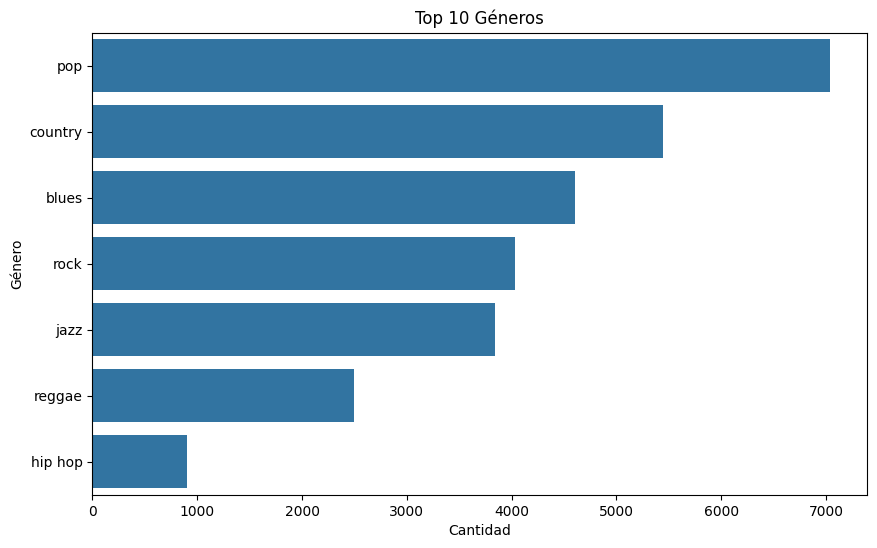

In [4]:
plt.figure(figsize=(10, 6))
sns.countplot(y='genre', data=data, order=data['genre'].value_counts().index[:10])
plt.title('Top 10 Géneros')
plt.xlabel('Cantidad')
plt.ylabel('Género')
plt.show()

Intentamos realizar dicha operacion con todos los géneros presentes en el dataset.

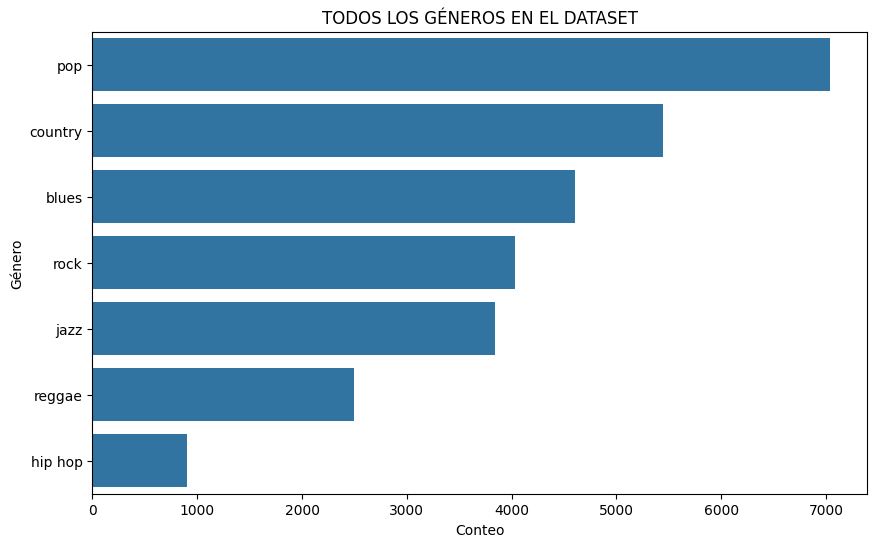

In [21]:
# Crear un DataFrame "largo" donde cada género tenga su propia fila
data_generos = data['genre'].str.split(', ').explode()

# Ahora graficas usando este nuevo set de datos limpios
plt.figure(figsize=(10, 6))
sns.countplot(y=data_generos, order=data_generos.value_counts().index[:10])
plt.title('TODOS LOS GÉNEROS EN EL DATASET')
plt.xlabel('Conteo')
plt.ylabel('Género')
plt.show()

Son los mismos géneros.

### Artistas con más Canciones

Identificamos a los artistas más populares según la cantidad de canciones que tienen en el dataset.

/tmp/ipykernel_6406/3783982030.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_artists.values, y=top_artists.index, palette='viridis')


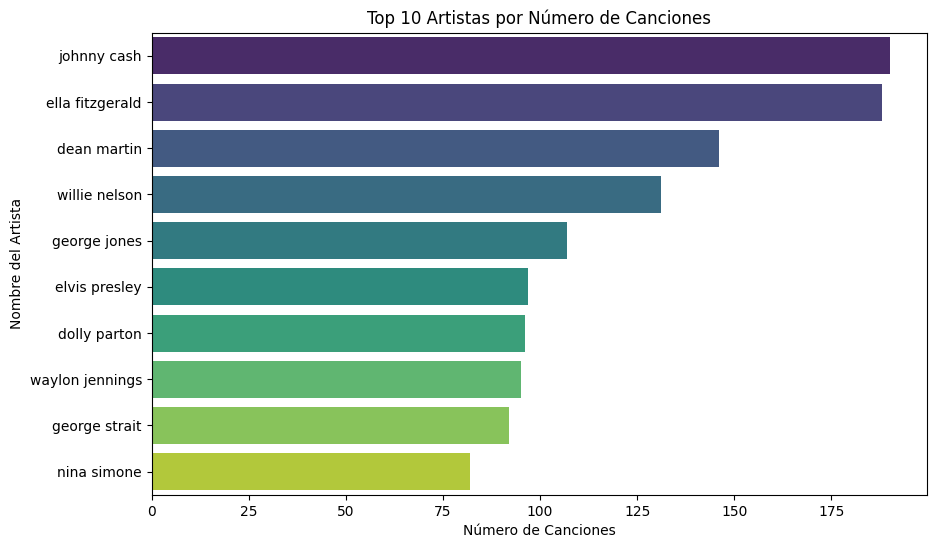

In [22]:
top_artists = data.groupby('artist_name').size().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_artists.values, y=top_artists.index, palette='viridis')
plt.title('Top 10 Artistas por Número de Canciones')
plt.xlabel('Número de Canciones')
plt.ylabel('Nombre del Artista')
plt.show()

## Paso 3: Preprocesamiento de los Datos

Para construir el sistema de recomendación, preprocesamos los datos combinando las características relevantes y convirtiéndolas en vectores numéricos.

### Combinar Características

Concatenamos las columnas `genre`, `artist_name` y `track_name` en una sola característica llamada `combined_features`.

In [3]:
data['combined_features'] = (
    data['genre'].fillna('') + ' ' +
    data['artist_name'].fillna('') + ' ' +
    data['track_name'].fillna('')
)

In [5]:
data['combined_features'].head()

,combined_features
0,pop mukesh mohabbat bhi jhoothi
1,pop frankie laine i believe
2,pop johnnie ray cry
3,pop pérez prado patricia
4,pop giorgos papadopoulos apopse eida oneiro


### Vectorizar los Datos de Texto

Usamos la **Vectorización TF-IDF** para convertir las características combinadas en vectores numéricos.

In [4]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(data['combined_features'])

In [8]:
print(tfidf_matrix)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 132224 stored elements and shape (28372, 14090)>
  Coords	Values
  (0, 9604)	0.11536855680551501
  (0, 8400)	0.47626007211345067
  (0, 8222)	0.4901460443797733
  (0, 1259)	0.5097172230707752
  (0, 6416)	0.5097172230707752
  (1, 9604)	0.18442616674381904
  (1, 4681)	0.5649249939399976
  (1, 6935)	0.6298007734648435
  (1, 1179)	0.5001976869050472
  (2, 9604)	0.21728774823785102
  (2, 6457)	0.7971242325416071
  (2, 10083)	0.5633639963297956
  (3, 9604)	0.12957485938200777
  (3, 9892)	0.5724829999851911
  (3, 9670)	0.5724829999851911
  (3, 9227)	0.5724829999851911
  (4, 9604)	0.10070699108895978
  (4, 5025)	0.44494001886677
  (4, 9128)	0.44494001886677
  (4, 623)	0.44494001886677
  (4, 3916)	0.44494001886677
  (4, 8892)	0.44494001886677
  (5, 9604)	0.08509901183469781
  (5, 10083)	0.22063701142704648
  (5, 9338)	0.2579826476706643
  :	:
  (28366, 10538)	0.534833342285826
  (28366, 10940)	0.7082070260230846
  (28367, 13577)	0.338

### Calcular Puntuaciones de Similitud

Calculamos la **similitud coseno** entre canciones a partir de sus características vectorizadas.

In [7]:
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

def get_recommendations(song_title, data, cosine_sim, top_n=10):
    # Obtener el índice de la canción que coincide con el título
    idx = data[data['track_name'] == song_title].index
    if len(idx) == 0:
        print("Canción no encontrada en el dataset.")
        return

    idx = idx[0]

    # Calcular puntuaciones de similitud con todas las demás canciones
    sim_scores = list(enumerate(cosine_sim[idx]))

    # Ordenar de mayor a menor similitud
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Excluir la misma canción (posición 0) y tomar las top_n más similares
    sim_scores = sim_scores[1:top_n+1]
    song_indices = [i[0] for i in sim_scores]

    recommendations = data.iloc[song_indices]
    return recommendations

**Explicación:**
- La función recupera el índice de la canción de entrada.
- Calcula las puntuaciones de similitud con todas las demás canciones y las ordena de forma descendente.
- Devuelve las N canciones más similares.

## Paso 4: Generar Recomendaciones

Usamos la función `get_recommendations` para recomendar canciones similares a una canción de entrada específica (por ejemplo, `'cry'`).

In [10]:
recommended_songs = get_recommendations('cry', data, cosine_sim, top_n=10)
print(recommended_songs[['track_name', 'artist_name', 'genre']])

                          track_name     artist_name  genre
56                         here am i     johnnie ray    pop
12887             keep on loving you  johnnie taylor  blues
15294              too many memories  johnnie taylor  blues
14542  there's nothing i wouldn't do  johnnie taylor  blues
14679                         lately  johnnie taylor  blues
13887                     steal away  johnnie taylor  blues
14701             don't make me late  johnnie taylor  blues
12881           baby, we've got love  johnnie taylor  blues
13247  i got to love somebody's baby  johnnie taylor  blues
12882            i need lots of love  johnnie taylor  blues


### Recomendaciones para "The winner takes it all", de ABBA. Una de las pocas canciones que conozco del dataset.

In [29]:
recommended_songs = get_recommendations('the winner takes it all', data, cosine_sim, top_n=10)
print(recommended_songs[['track_name', 'artist_name', 'genre']])

                         track_name         artist_name genre
2013   i do, i do, i do, i do, i do                abba   pop
2014                         s.o.s.                abba   pop
2702                      one of us                abba   pop
18537              you are a winner  earth, wind & fire  jazz
2454                 i have a dream                abba   pop
2115               my love, my life                abba   pop
1847                      watch out                abba   pop
2211             one man, one woman                abba   pop
2441                 kisses of fire                abba   pop
5615              whatever it takes           lifehouse   pop


Si analizamos los datos de la cancion a la que solicitamos recomendaciones, vemos que sus recomendaciones tienen valores similares. Por ejemplo, mismo grupo musical, mismo genero o mismos atributos de sentimientos.

In [30]:
cancion = data[data['track_name'] == 'the winner takes it all']
cancion

,Unnamed: 0,artist_name,track_name,release_date,genre,lyrics,len,dating,violence,world/life,...,feelings,danceability,loudness,acousticness,instrumentalness,valence,energy,topic,age,combined_features
2559,7661,abba,the winner takes it all,1980,pop,wanna talk things go hurt history play card pl...,109,0.000658,0.081275,0.000658,...,0.046205,0.428138,0.740302,0.5502,0.00079,0.513603,0.785779,sadness,0.571429,pop abba the winner takes it all


### Recomendaciones para Skyfall de Adele

In [31]:
recommended_songs = get_recommendations('skyfall', data, cosine_sim, top_n=10)
print(recommended_songs[['track_name', 'artist_name', 'genre']])

                  track_name artist_name genre
6086            one and only       adele   pop
6473                   hello       adele   pop
5670                   tired       adele   pop
6083      don't you remember       adele   pop
5651           right as rain       adele   pop
6681                  remedy       adele   pop
5957     rolling in the deep       adele   pop
5547         hiding my heart       adele   pop
5733  melt my heart to stone       adele   pop
5731          hometown glory       adele   pop


In [32]:
print(recommended_songs)

      Unnamed: 0 artist_name              track_name  release_date genre  \
6086       17532       adele            one and only          2011   pop   
6473       18638       adele                   hello          2015   pop   
5670       16333       adele                   tired          2008   pop   
6083       17519       adele      don't you remember          2011   pop   
5651       16270       adele           right as rain          2008   pop   
6681       19158       adele                  remedy          2016   pop   
5957       17185       adele     rolling in the deep          2010   pop   
5547       15960       adele         hiding my heart          2007   pop   
5733       16524       adele  melt my heart to stone          2008   pop   
5731       16519       adele          hometown glory          2008   pop   

                                                 lyrics  len    dating  \
6086  mind grow fonder lose time think face know tak...  113  0.000526   
6473  hello won

## Paso 5: Visualizar las Recomendaciones

Finalmente, visualizamos las canciones recomendadas usando un gráfico de barras.

/tmp/ipykernel_13474/1052093393.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='track_name', x='artist_name', data=recommended_songs, palette='coolwarm')


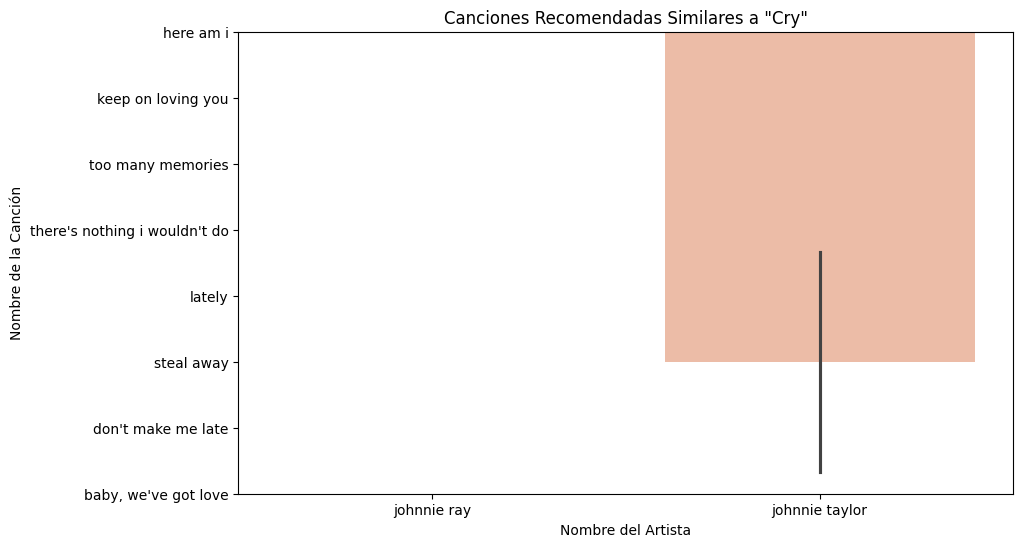

In [11]:
recommended_songs = get_recommendations('cry', data, cosine_sim, top_n=10)

plt.figure(figsize=(10, 6))
sns.barplot(y='track_name', x='artist_name', data=recommended_songs, palette='coolwarm')
plt.title('Canciones Recomendadas Similares a "Cry"')
plt.xlabel('Nombre del Artista')
plt.ylabel('Nombre de la Canción')
plt.show()

###Otra forma de visualizar las recomendaciones

/tmp/ipykernel_13474/1959202932.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Similitud', y='Canción', data=df_plot, palette='magma')


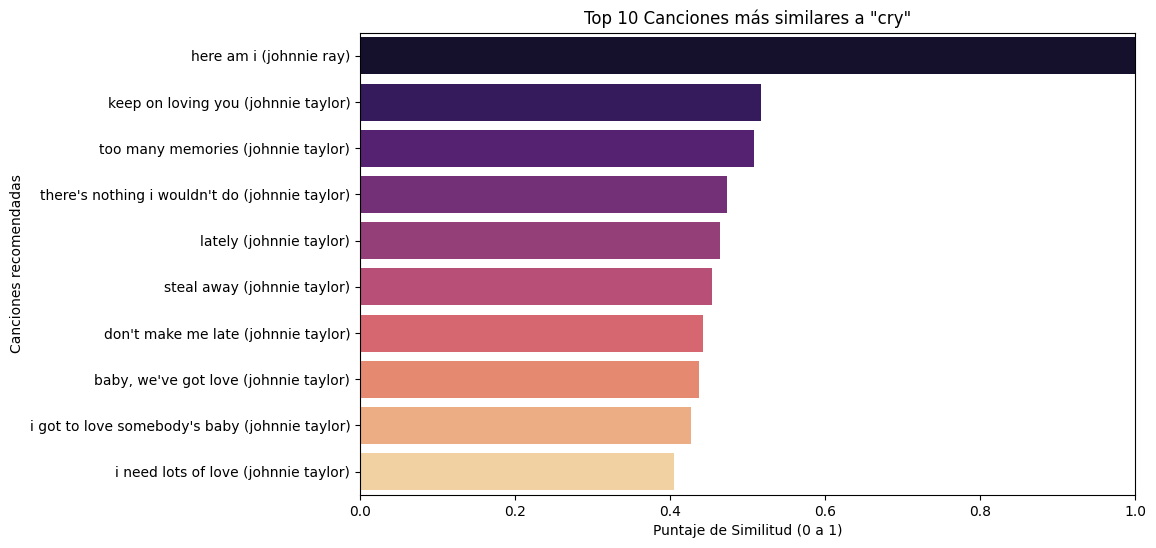

In [12]:
def plot_recommendations_with_scores(song_title, data, cosine_sim, top_n=10):
    song_title_clean = song_title.lower().strip()
    idx = data[data['track_name'].str.lower().str.strip() == song_title_clean].index[0]

    # Obtenemos los puntajes de similitud reales
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:top_n+1]

    # Creamos un dataframe temporal con los nombres y sus respectivos puntajes de similitud
    tracks = [data.iloc[i[0]]['track_name'] for i in sim_scores]
    artists = [data.iloc[i[0]]['artist_name'] for i in sim_scores]
    scores = [i[1] for i in sim_scores]

    df_plot = pd.DataFrame({
        'Canción': [f"{t} ({a})" for t, a in zip(tracks, artists)],
        'Similitud': scores
    })

    #Graficar
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Similitud', y='Canción', data=df_plot, palette='magma')
    plt.title(f'Top {top_n} Canciones más similares a "{song_title}"')
    plt.xlabel('Puntaje de Similitud (0 a 1)')
    plt.ylabel('Canciones recomendadas')
    plt.xlim(0, 1) # El límite de la similitud de coseno es 1
    plt.show()

# Ejemplo de uso:
plot_recommendations_with_scores('cry', data, cosine_sim, top_n=10)

------------
##Otra forma de analizar y presentar el gráfico de recomendaciones

Esta es una propuesta de la función get_recommendations con validaciones

In [5]:
def get_recommendations_improved(song_title, data, cosine_sim, top_n=10):
    #Convertimos el título buscado a minúsculas y limpiamos espacios vacíos
    song_title_clean = song_title.lower().strip()

    #Buscamos de manera insensible a mayúsculas/minúsculas
    idx = data[data['track_name'].str.lower().str.strip() == song_title_clean].index

    if len(idx) == 0:
        print(f"La canción '{song_title}' no fue encontrada en el dataset.")
        return None

    idx = idx[0]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    #Evitar recomendar la misma canción que se introdujo
    sim_scores = sim_scores[1:top_n+1]
    song_indices = [i[0] for i[0] in sim_scores]

    return data.iloc[song_indices]

Normalización de los atributos numéricos en el dataset. Se agregan a la matriz de recomendaciones.

In [6]:
from sklearn.preprocessing import MinMaxScaler
from scipy.sparse import hstack

# 1. Seleccionar las columnas numéricas
numerical_cols = ['danceability', 'loudness', 'acousticness', 'energy', 'instrumentalness', 'valence']

# 2. RELLENAR VALORES NAN: Usamos la mediana de cada columna
for col in numerical_cols:
    data[col] = data[col].fillna(data[col].median())

# 3. Ahora sí, aplicar el escalador de manera segura
scaler = MinMaxScaler()
numerical_scaled = scaler.fit_transform(data[numerical_cols])

# 4. Combinar con tu matriz de texto (TF-IDF)
combined_matrix = hstack([tfidf_matrix, numerical_scaled])

In [ ]:
cosine_sim_hybrid = cosine_similarity(combined_matrix, combined_matrix)

def plot_recommendations_with_scores(song_title, data, cosine_sim, top_n=10):
    song_title_clean = song_title.lower().strip()
    idx = data[data['track_name'].str.lower().str.strip() == song_title_clean].index[0]

    # Obtenemos los puntajes de similitud reales
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:top_n+1]

    # Creamos un dataframe temporal con los nombres y sus respectivos puntajes de similitud
    tracks = [data.iloc[i[0]]['track_name'] for i in sim_scores]
    artists = [data.iloc[i[0]]['artist_name'] for i in sim_scores]
    scores = [i[1] for i in sim_scores]

    df_plot = pd.DataFrame({
        'Canción': [f"{t} ({a})" for t, a in zip(tracks, artists)],
        'Similitud': scores
    })

    # Graficar correctamente
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Similitud', y='Canción', data=df_plot, palette='magma')
    plt.title(f'Top {top_n} Canciones más similares a "{song_title}"')
    plt.xlabel('Puntaje de Similitud (0 a 1)')
    plt.ylabel('Canciones recomendadas')
    plt.xlim(0, 1) # El límite de la similitud de coseno es 1
    plt.show()

# Ejemplo de uso:
plot_recommendations_with_scores('cry', data, cosine_sim_hybrid, top_n=10)

Le juro que esta última parte si funciona, pero el datset me consumió toda la RAM de mi sesión en Colab y hace que crashee cuando intento ejecutar esto último.

---

## Conclusión

Aunque este modelo requiere muchos ajustes antes de poder usarse en una aplicación o sitio web de música real, este notebook ofrece una visión general de cómo se construyen y utilizan los **sistemas de recomendación** con Machine Learning.